# Frequency-Modellierung mit Poisson Regression

Ziel dieses Notebooks ist die Entwicklung und Bewertung des finalen
Poisson-Frequenzmodells auf Basis eines einmalig definierten,
reproduzierbaren Policy-Level-Train/Test-Splits.

Die Modellbewertung erfolgt ausschließlich auf dem Holdout-Testdatensatz.

In [1]:
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split


PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "policy_curated.pq"

print(f"Project root: {PROJECT_ROOT}")
print(f"Data path:    {DATA_PATH}")
print(f"Exists:       {DATA_PATH.exists()}")

Project root: c:\Users\Mesut\Desktop\kfz-insurance-risk-platform
Data path:    c:\Users\Mesut\Desktop\kfz-insurance-risk-platform\data\processed\policy_curated.pq
Exists:       True


In [2]:
df = pd.read_parquet(DATA_PATH)

print(f"Rows:    {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

display(df.head(3))

print("\nColumns:")
print(df.columns.tolist())

Rows:    678,013
Columns: 25


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,...,claim_record_count,claim_count_mismatch,missing_severity,observed_claim_frequency,observed_severity,observed_pure_premium,driver_age_group,vehicle_age_group,bonus_malus_segment,log_density
0,1.0,1,0.10,D,5,0,55,50,B12,Regular,...,NaN,False,True,10.000000,NaN,NaN,55-64,0-2,50,7.104965
1,3.0,1,0.77,D,5,0,55,50,B12,Regular,...,NaN,False,True,1.298701,NaN,NaN,55-64,0-2,50,7.104965
2,5.0,1,0.75,B,6,2,52,50,B12,Diesel,...,NaN,False,True,1.333333,NaN,NaN,45-54,0-2,50,4.007333



Columns:
['IDpol', 'ClaimNb', 'Exposure', 'Area', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'VehBrand', 'VehGas', 'Density', 'Region', 'exposure_capped', 'high_claim_count', 'total_claim_amount', 'claim_record_count', 'claim_count_mismatch', 'missing_severity', 'observed_claim_frequency', 'observed_severity', 'observed_pure_premium', 'driver_age_group', 'vehicle_age_group', 'bonus_malus_segment', 'log_density']


## Gemeinsamer Policy-Level-Train/Test-Split

Der Train/Test-Split wird einmalig auf Policy-Ebene erstellt und anschließend
für Frequency- und Severity-Modellierung gemeinsam verwendet.

Vor der Aufteilung wird die Eindeutigkeit und Konsistenz von `IDpol` geprüft.

In [3]:
print(f"IDpol dtype:          {df['IDpol'].dtype}")
print(f"Missing IDpol:        {df['IDpol'].isna().sum():,}")
print(f"Duplicate IDpol:      {df['IDpol'].duplicated().sum():,}")
print(f"Unique IDpol:         {df['IDpol'].nunique():,}")
print(f"Total rows:           {len(df):,}")

idpol_integer_like = ((df["IDpol"] % 1) == 0).all()
print(f"IDpol integer-like:   {idpol_integer_like}")

IDpol dtype:          float64
Missing IDpol:        0
Duplicate IDpol:      0
Unique IDpol:         678,013
Total rows:           678,013
IDpol integer-like:   True


### Erstellung des gemeinsamen Splits

Die Policen werden im Verhältnis 80/20 in Train- und Testdaten aufgeteilt.
Zur Reproduzierbarkeit wird `random_state=42` verwendet.

Da Schadenfälle im Portfolio vergleichsweise selten sind, wird nach dem
Indikator `ClaimNb > 0` stratifiziert. Dadurch bleibt der Anteil der
Policen mit mindestens einem Schaden in beiden Teilmengen vergleichbar.

In [4]:
# IDpol wurde zuvor als eindeutig und ganzzahlig geprüft.
df["IDpol"] = df["IDpol"].astype("int64")

has_claim = df["ClaimNb"].gt(0)

train_ids, test_ids = train_test_split(
    df["IDpol"],
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=has_claim,
)

print(f"Train policies: {len(train_ids):,}")
print(f"Test policies:  {len(test_ids):,}")
print(f"Total policies: {len(train_ids) + len(test_ids):,}")

Train policies: 542,410
Test policies:  135,603
Total policies: 678,013


### Validierung des Train/Test-Splits

Der gemeinsame Split wird auf Überschneidungen, Eindeutigkeit und eine
vergleichbare Verteilung zentraler Portfolio-Kennzahlen geprüft.

Zusätzlich wird kontrolliert, wie viele für das Severity-Modell geeignete
Policen in Train und Test enthalten sind.

In [5]:
split_assignment = pd.DataFrame({
    "IDpol": pd.concat([train_ids, test_ids], ignore_index=True),
    "split": (
        ["train"] * len(train_ids)
        + ["test"] * len(test_ids)
    )
})

df_model = df.merge(
    split_assignment,
    on="IDpol",
    how="left",
    validate="one_to_one",
)

print(df_model["split"].value_counts())
print(f"\nMissing split labels: {df_model['split'].isna().sum():,}")

split
train    542410
test     135603
Name: count, dtype: int64

Missing split labels: 0


In [6]:
train_df = df_model[df_model["split"] == "train"].copy()
test_df = df_model[df_model["split"] == "test"].copy()

train_id_set = set(train_df["IDpol"])
test_id_set = set(test_df["IDpol"])

intersection = train_id_set.intersection(test_id_set)

print("=== Split Integrity ===")
print(f"Train rows:              {len(train_df):,}")
print(f"Test rows:               {len(test_df):,}")
print(f"Train unique IDpol:      {train_df['IDpol'].nunique():,}")
print(f"Test unique IDpol:       {test_df['IDpol'].nunique():,}")
print(f"Train/Test intersection: {len(intersection):,}")

print("\n=== Claim Distribution ===")
print(
    f"Train policies with claim: "
    f"{train_df['ClaimNb'].gt(0).mean():.4%}"
)
print(
    f"Test policies with claim:  "
    f"{test_df['ClaimNb'].gt(0).mean():.4%}"
)

print("\n=== Exposure ===")
print(f"Train total exposure: {train_df['Exposure'].sum():,.2f}")
print(f"Test total exposure:  {test_df['Exposure'].sum():,.2f}")
print(f"Train mean exposure:  {train_df['Exposure'].mean():.4f}")
print(f"Test mean exposure:   {test_df['Exposure'].mean():.4f}")

print("\n=== Portfolio Frequency ===")
print(f"Train actual claims: {train_df['ClaimNb'].sum():,.0f}")
print(f"Test actual claims:  {test_df['ClaimNb'].sum():,.0f}")

train_frequency = (
    train_df["ClaimNb"].sum()
    / train_df["Exposure"].sum()
)

test_frequency = (
    test_df["ClaimNb"].sum()
    / test_df["Exposure"].sum()
)

print(f"Train frequency: {train_frequency:.6f}")
print(f"Test frequency:  {test_frequency:.6f}")

=== Split Integrity ===
Train rows:              542,410
Test rows:               135,603
Train unique IDpol:      542,410
Test unique IDpol:       135,603
Train/Test intersection: 0

=== Claim Distribution ===
Train policies with claim: 5.0235%
Test policies with claim:  5.0235%

=== Exposure ===
Train total exposure: 286,776.50
Test total exposure:  71,583.60
Train mean exposure:  0.5287
Test mean exposure:   0.5279

=== Portfolio Frequency ===
Train actual claims: 28,866
Test actual claims:  7,236
Train frequency: 0.100657
Test frequency:  0.101085


In [7]:
severity_mask = (
    df_model["ClaimNb"].gt(0)
    & df_model["total_claim_amount"].notna()
    & df_model["total_claim_amount"].gt(0)
    & ~df_model["missing_severity"]
    & ~df_model["claim_count_mismatch"]
)

severity_split_counts = (
    df_model.loc[severity_mask, "split"]
    .value_counts()
    .reindex(["train", "test"])
)

print("=== Severity-Eligible Policies ===")
print(severity_split_counts)

print(
    f"\nTotal severity-eligible policies: "
    f"{severity_mask.sum():,}"
)

=== Severity-Eligible Policies ===
split
train    19944
test      4999
Name: count, dtype: int64

Total severity-eligible policies: 24,943


**Ergebnis:** Der gemeinsame Policy-Level-Split ist konsistent und frei von
Train/Test-Überschneidungen. Claim-Anteil, Exposure und beobachtete
Schadenhäufigkeit sind zwischen Train und Test vergleichbar.

Für die Severity-Modellierung stehen 19.944 Trainings- und 4.999
Testpolicen zur Verfügung.

In [8]:
SPLIT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "policy_train_test_split.pq"
)

split_assignment = (
    split_assignment
    .sort_values("IDpol")
    .reset_index(drop=True)
)

split_assignment.to_parquet(
    SPLIT_PATH,
    index=False,
)

print(f"Saved to: {SPLIT_PATH}")
print(f"Rows:     {len(split_assignment):,}")
print(f"Exists:   {SPLIT_PATH.exists()}")

Saved to: c:\Users\Mesut\Desktop\kfz-insurance-risk-platform\data\processed\policy_train_test_split.pq
Rows:     678,013
Exists:   True


In [9]:
saved_split = pd.read_parquet(SPLIT_PATH)

print("=== Saved Split Validation ===")
print(f"Rows:               {len(saved_split):,}")
print(f"Unique IDpol:       {saved_split['IDpol'].nunique():,}")
print(f"Missing IDpol:      {saved_split['IDpol'].isna().sum():,}")
print(f"Missing split:      {saved_split['split'].isna().sum():,}")
print(f"Duplicate IDpol:    {saved_split['IDpol'].duplicated().sum():}")

print("\nSplit counts:")
print(saved_split["split"].value_counts())

same_assignment = (
    split_assignment
    .sort_values("IDpol")
    .reset_index(drop=True)
    .equals(
        saved_split
        .sort_values("IDpol")
        .reset_index(drop=True)
    )
)

print(f"\nSaved assignment identical: {same_assignment}")

=== Saved Split Validation ===
Rows:               678,013
Unique IDpol:       678,013
Missing IDpol:      0
Missing split:      0
Duplicate IDpol:    0

Split counts:
split
train    542410
test     135603
Name: count, dtype: int64

Saved assignment identical: True


**Ergebnis:** Der gemeinsame Policy-Level-Train/Test-Split wurde erfolgreich
validiert und dauerhaft gespeichert. Alle 678.013 Policen besitzen genau eine
Split-Zuordnung, und zwischen Train und Test bestehen keine Überschneidungen.

Der gespeicherte Split wird unverändert für Frequency- und Severity-Modellierung
verwendet.

## Feature-Auswahl und Leakage-Prüfung

Vor der Modellierung werden alle Variablen nach ihrer Rolle klassifiziert.
Ziel ist es, Target-Leakage zu vermeiden und nur fachlich sinnvolle,
zum Prognosezeitpunkt verfügbare Merkmale zu verwenden.

In [10]:
feature_audit = pd.DataFrame({
    "column": df_model.columns,
    "dtype": df_model.dtypes.astype(str).values,
    "missing_count": df_model.isna().sum().values,
    "n_unique": df_model.nunique(dropna=True).values,
})

feature_audit

,column,dtype,missing_count,n_unique
0,IDpol,int64,0,678013
1,ClaimNb,uint8,0,11
2,Exposure,float64,0,106
3,Area,category,0,6
4,VehPower,uint8,0,12
5,VehAge,uint8,0,78
6,DrivAge,uint8,0,83
7,BonusMalus,uint8,0,115
8,VehBrand,category,0,11
9,VehGas,object,0,2


### Klassifikation der Variablen

Die verfügbaren Variablen werden nach ihrer Rolle im Modellierungsprozess
klassifiziert. Ziel- und Schadeninformationen sowie technische Metadaten
werden konsequent von den potenziellen Prädiktoren getrennt.

Abgeleitete Merkmale werden nur dann gemeinsam mit ihren Ursprungsvariablen
verwendet, wenn daraus ein zusätzlicher analytischer Nutzen entsteht.

In [11]:
feature_roles = pd.DataFrame([
    ("IDpol", "Identifier", "Nein",
     "Technischer Policy-Schlüssel, kein Risikomerkmal."),

    ("ClaimNb", "Target", "Nein",
     "Zielvariable des Frequency-Modells."),

    ("Exposure", "Exposure / Weight", "Nein",
     "Wird zur Annualisierung und als sample_weight verwendet."),

    ("Area", "Categorical Candidate", "Prüfen",
     "Geografisches Risikomerkmal mit niedriger Kardinalität."),

    ("VehPower", "Numeric Candidate", "Prüfen",
     "Fahrzeugbezogenes Risikomerkmal."),

    ("VehAge", "Numeric Candidate", "Prüfen",
     "Rohmerkmal; mögliche Redundanz mit vehicle_age_group."),

    ("DrivAge", "Numeric Candidate", "Prüfen",
     "Rohmerkmal; mögliche Redundanz mit driver_age_group."),

    ("BonusMalus", "Numeric Candidate", "Prüfen",
     "Rohmerkmal; mögliche Redundanz mit bonus_malus_segment."),

    ("VehBrand", "Categorical Candidate", "Prüfen",
     "Fahrzeugbezogenes kategoriales Merkmal."),

    ("VehGas", "Categorical Candidate", "Prüfen",
     "Antriebsart mit niedriger Kardinalität."),

    ("Density", "Numeric Candidate", "Prüfen",
     "Stark schiefe Rohvariable; mögliche Redundanz mit log_density."),

    ("Region", "Categorical Candidate", "Prüfen",
     "Geografisches Merkmal mit 22 Kategorien."),

    ("exposure_capped", "DQ / Processing Flag", "Nein",
     "Kennzeichnet eine technische Bereinigungsentscheidung, kein originäres Risikomerkmal."),

    ("high_claim_count", "Target Leakage", "Nein",
     "Direkt aus ClaimNb und damit aus der Zielvariable abgeleitet."),

    ("total_claim_amount", "Post-Outcome / Leakage", "Nein",
     "Schadenhöhe ist erst nach Eintritt eines Schadens bekannt."),

    ("claim_record_count", "Post-Outcome / Leakage", "Nein",
     "Aus vorhandenen Schadenmeldungen abgeleitet."),

    ("claim_count_mismatch", "Post-Outcome / DQ", "Nein",
     "Entsteht erst durch den Abgleich von Frequency- und Severity-Daten."),

    ("missing_severity", "Post-Outcome / DQ", "Nein",
     "Information über die Verfügbarkeit nachgelagerter Schadendaten."),

    ("observed_claim_frequency", "Target Leakage", "Nein",
     "Direkt aus ClaimNb und Exposure berechnet."),

    ("observed_severity", "Target Leakage", "Nein",
     "Aus realisierten Schadenbeträgen berechnet."),

    ("observed_pure_premium", "Target Leakage", "Nein",
     "Aus realisierten Schadendaten berechnet."),

    ("driver_age_group", "Engineered Candidate", "Prüfen",
     "Nichtlinearität von DrivAge; nicht automatisch zusammen mit DrivAge verwenden."),

    ("vehicle_age_group", "Engineered Candidate", "Prüfen",
     "Gruppierte Form von VehAge."),

    ("bonus_malus_segment", "Engineered Candidate", "Prüfen",
     "Gruppierte Form von BonusMalus."),

    ("log_density", "Engineered Numeric Candidate", "Prüfen",
     "Log-transformierte Form der stark schiefen Density-Variable."),

    ("split", "Split Metadata", "Nein",
     "Nur technische Train/Test-Zuordnung.")
], columns=["column", "role", "frequency_predictor", "reason"])

display(feature_roles)

,column,role,frequency_predictor,reason
0,IDpol,Identifier,Nein,"Technischer Policy-Schlüssel, kein Risikomerkmal."
1,ClaimNb,Target,Nein,Zielvariable des Frequency-Modells.
2,Exposure,Exposure / Weight,Nein,Wird zur Annualisierung und als sample_weight ...
3,Area,Categorical Candidate,Prüfen,Geografisches Risikomerkmal mit niedriger Kard...
4,VehPower,Numeric Candidate,Prüfen,Fahrzeugbezogenes Risikomerkmal.
5,VehAge,Numeric Candidate,Prüfen,Rohmerkmal; mögliche Redundanz mit vehicle_age...
6,DrivAge,Numeric Candidate,Prüfen,Rohmerkmal; mögliche Redundanz mit driver_age_...
7,BonusMalus,Numeric Candidate,Prüfen,Rohmerkmal; mögliche Redundanz mit bonus_malus...
8,VehBrand,Categorical Candidate,Prüfen,Fahrzeugbezogenes kategoriales Merkmal.
9,VehGas,Categorical Candidate,Prüfen,Antriebsart mit niedriger Kardinalität.


### Prüfung potenziell redundanter Merkmale

Vor der finalen Feature-Auswahl werden inhaltlich verwandte Roh- und
abgeleitete Merkmale untersucht. Dadurch soll vermieden werden, dieselbe
Information unnötig mehrfach in das Modell aufzunehmen.

In [12]:
redundancy_pairs = [
    ("DrivAge", "driver_age_group"),
    ("VehAge", "vehicle_age_group"),
    ("BonusMalus", "bonus_malus_segment"),
    ("Density", "log_density"),
]

print("=== Raw / Engineered Feature Pairs ===")

for raw_col, engineered_col in redundancy_pairs:
    print(f"\n{raw_col} ↔ {engineered_col}")
    print(f"  {raw_col} unique values:        {df_model[raw_col].nunique():,}")
    print(f"  {engineered_col} unique values: {df_model[engineered_col].nunique():,}")

print("\n=== Geographic Features ===")
print(f"Area categories:   {df_model['Area'].nunique()}")
print(f"Region categories: {df_model['Region'].nunique()}")
print(f"Density values:    {df_model['Density'].nunique():,}")

print("\nRegions per Area:")
display(
    df_model.groupby("Area", observed=True)["Region"]
    .nunique()
    .rename("n_regions")
    .to_frame()
)

print("Areas per Region:")
display(
    df_model.groupby("Region", observed=True)["Area"]
    .nunique()
    .rename("n_areas")
    .to_frame()
)

=== Raw / Engineered Feature Pairs ===

DrivAge ↔ driver_age_group
  DrivAge unique values:        83
  driver_age_group unique values: 7

VehAge ↔ vehicle_age_group
  VehAge unique values:        78
  vehicle_age_group unique values: 6

BonusMalus ↔ bonus_malus_segment
  BonusMalus unique values:        115
  bonus_malus_segment unique values: 5

Density ↔ log_density
  Density unique values:        1,607
  log_density unique values: 1,607

=== Geographic Features ===
Area categories:   6
Region categories: 22
Density values:    1,607

Regions per Area:


,n_regions
Area,
A,22
B,22
C,22
D,22
E,20
F,1


Areas per Region:


,n_areas
Region,
R11,6
R21,5
R22,5
R23,5
R24,5
R25,5
R26,5
R31,5
R41,5


In [13]:
density_by_area = (
    df_model.groupby("Area", observed=True)["Density"]
    .agg(
        count="size",
        min_density="min",
        median_density="median",
        max_density="max",
        unique_density="nunique",
    )
)

display(density_by_area)

,count,min_density,median_density,max_density,unique_density
Area,,,,,
A,103957,1.0,27.0,50.0,50
B,75459,50.0,72.0,100.0,51
C,191880,100.0,222.0,500.0,395
D,151596,500.0,1054.0,1993.0,718
E,137167,2001.0,3744.0,9850.0,367
F,17954,10008.0,27000.0,27000.0,29


### Finale Feature-Auswahl für das Frequency-Modell

Für das Poisson-Modell werden ausschließlich Merkmale verwendet, die zum
Prognosezeitpunkt verfügbar sind. Stark verwandte Roh- und abgeleitete
Variablen werden nicht gleichzeitig verwendet.

Für Alter und Bonus-Malus werden die aus der EDA abgeleiteten Gruppen
verwendet. `log_density` ersetzt sowohl die stark schiefe Rohvariable
`Density` als auch die gröbere Gebietsklasse `Area`.

In [14]:
categorical_features = [
    "VehPower",
    "VehBrand",
    "VehGas",
    "Region",
    "driver_age_group",
    "vehicle_age_group",
    "bonus_malus_segment",
]

numeric_features = [
    "log_density",
]

frequency_features = categorical_features + numeric_features

print(f"Categorical features: {len(categorical_features)}")
print(f"Numeric features:     {len(numeric_features)}")
print(f"Total predictors:     {len(frequency_features)}")

print("\nFinal frequency predictors:")
for feature in frequency_features:
    print(f"- {feature}")

Categorical features: 7
Numeric features:     1
Total predictors:     8

Final frequency predictors:
- VehPower
- VehBrand
- VehGas
- Region
- driver_age_group
- vehicle_age_group
- bonus_malus_segment
- log_density


### Prüfung auf fehlende und unbekannte Kategorien

Vor dem Preprocessing wird geprüft, ob die ausgewählten Modellvariablen
fehlende Werte enthalten und ob im Testdatensatz Kategorien vorkommen,
die im Trainingsdatensatz nicht vorhanden sind.

In [15]:
print("=== Missing Values ===")

missing_summary = (
    df_model[frequency_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print(missing_summary)


print("\n=== Unseen Categories in Test ===")

for col in categorical_features:
    train_categories = set(train_df[col].dropna().astype(str).unique())
    test_categories = set(test_df[col].dropna().astype(str).unique())

    unseen = test_categories - train_categories

    print(f"{col}: {len(unseen)} unseen categories")

    if unseen:
        print(f"  {sorted(unseen)}")

=== Missing Values ===
VehPower               0
VehBrand               0
VehGas                 0
Region                 0
driver_age_group       0
vehicle_age_group      0
bonus_malus_segment    0
log_density            0
dtype: int64

=== Unseen Categories in Test ===
VehPower: 0 unseen categories
VehBrand: 0 unseen categories
VehGas: 0 unseen categories
Region: 0 unseen categories
driver_age_group: 0 unseen categories
vehicle_age_group: 0 unseen categories
bonus_malus_segment: 0 unseen categories


## Vorbereitung der Modelldaten

Die Schadenhäufigkeit wird als Anzahl der Schäden pro Exposure-Einheit
modelliert. Die Exposure wird dabei nicht als Prädiktor verwendet, sondern
als Gewicht der jeweiligen Police berücksichtigt.

\[
y = \frac{ClaimNb}{Exposure}
\]

mit

\[
sample\_weight = Exposure
\]

In [16]:
print("=== Exposure Safety Check ===")
print(f"Minimum Exposure: {df_model['Exposure'].min():.6f}")
print(f"Zero Exposure:    {(df_model['Exposure'] == 0).sum():,}")
print(f"Negative Exposure:{(df_model['Exposure'] < 0).sum():,}")


X_train = train_df[frequency_features].copy()
X_test = test_df[frequency_features].copy()

y_train = train_df["ClaimNb"] / train_df["Exposure"]
y_test = test_df["ClaimNb"] / test_df["Exposure"]

w_train = train_df["Exposure"].copy()
w_test = test_df["Exposure"].copy()


print("\n=== Model Data ===")
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")

print(f"\ny_train observations: {len(y_train):,}")
print(f"y_test observations:  {len(y_test):,}")

print(f"\nTrain exposure: {w_train.sum():,.2f}")
print(f"Test exposure:  {w_test.sum():,.2f}")

=== Exposure Safety Check ===
Minimum Exposure: 0.002732
Zero Exposure:    0
Negative Exposure:0

=== Model Data ===
X_train: (542410, 8)
X_test:  (135603, 8)

y_train observations: 542,410
y_test observations:  135,603

Train exposure: 286,776.50
Test exposure:  71,583.60


## Baseline-Modell

Als Referenz wird zunächst ein einfaches Baseline-Modell verwendet.
Es weist jeder Police die exposure-gewichtete Schadenhäufigkeit des
Trainingsportfolios als konstante Prognose zu.

Das Baseline-Modell dient als Vergleichsmaßstab für das spätere
Poisson-Modell.

In [17]:
import numpy as np
from sklearn.metrics import mean_poisson_deviance


baseline_frequency = (
    train_df["ClaimNb"].sum()
    / train_df["Exposure"].sum()
)

baseline_pred_test = np.full(
    shape=len(test_df),
    fill_value=baseline_frequency,
    dtype=float,
)

baseline_deviance = mean_poisson_deviance(
    y_test,
    baseline_pred_test,
    sample_weight=w_test,
)

baseline_expected_claims = (
    baseline_pred_test * w_test
).sum()

actual_test_claims = test_df["ClaimNb"].sum()

print("=== Frequency Baseline ===")
print(f"Train portfolio frequency: {baseline_frequency:.6f}")
print(f"Test portfolio frequency:  {actual_test_claims / w_test.sum():.6f}")

print(f"\nMean Poisson Deviance:     {baseline_deviance:.6f}")

print("\n=== Test Portfolio Check ===")
print(f"Actual claims:              {actual_test_claims:,.0f}")
print(f"Baseline expected claims:   {baseline_expected_claims:,.2f}")
print(
    f"Difference:                 "
    f"{baseline_expected_claims - actual_test_claims:,.2f}"
)

=== Frequency Baseline ===
Train portfolio frequency: 0.100657
Test portfolio frequency:  0.101085

Mean Poisson Deviance:     0.625748

=== Test Portfolio Check ===
Actual claims:              7,236
Baseline expected claims:   7,205.38
Difference:                 -30.62


## Preprocessing

Kategoriale Merkmale werden mittels One-Hot-Encoding transformiert.
Numerische Merkmale werden unverändert an das Poisson-Modell übergeben.

Unbekannte Kategorien werden ignoriert, damit die Pipeline auch bei
zukünftigen Daten robust bleibt.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder


preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
            ),
            categorical_features,
        ),
        (
            "numeric",
            "passthrough",
            numeric_features,
        ),
    ],
    remainder="drop",
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fe

## Poisson-Regressionsmodell

Das Frequency-Modell wird als Poisson-GLM ohne zusätzliche Regularisierung
geschätzt. Die kategorialen Variablen werden mit Referenzkategorien kodiert.

Die Exposure fließt als `sample_weight` in die Modellschätzung ein.

In [19]:
from sklearn.linear_model import PoissonRegressor
from sklearn.pipeline import Pipeline


frequency_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            PoissonRegressor(
                alpha=0.0,
                max_iter=1000,
            ),
        ),
    ]
)

frequency_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defau

### Modelltraining

Das Poisson-Modell wird ausschließlich auf den Trainingsdaten geschätzt.
Die Exposure jeder Police wird dabei als Gewicht berücksichtigt.

Der Testdatensatz bleibt während des Trainings vollständig unberührt.

In [20]:
frequency_pipeline.fit(
    X_train,
    y_train,
    model__sample_weight=w_train,
)

print("Poisson model fitted successfully.")

Poisson model fitted successfully.


### Prüfung der Modellprognosen

Nach dem Training werden die Prognosen auf dem Holdout-Testdatensatz
zunächst technisch validiert. Dabei werden insbesondere fehlende,
unendliche oder nicht-positive Vorhersagen ausgeschlossen.

In [21]:
y_pred_test = frequency_pipeline.predict(X_test)

poisson_model = frequency_pipeline.named_steps["model"]

print("=== Poisson Prediction Sanity Check ===")
print(f"Predictions:          {len(y_pred_test):,}")
print(f"NaN predictions:      {np.isnan(y_pred_test).sum():,}")
print(f"Infinite predictions: {np.isinf(y_pred_test).sum():,}")
print(f"Non-positive preds:   {(y_pred_test <= 0).sum():,}")

print("\n=== Prediction Range ===")
print(f"Minimum: {y_pred_test.min():.6f}")
print(f"Mean:    {y_pred_test.mean():.6f}")
print(f"Median:  {np.median(y_pred_test):.6f}")
print(f"Maximum: {y_pred_test.max():.6f}")

print("\n=== Optimizer ===")
print(f"Iterations used: {poisson_model.n_iter_}")

=== Poisson Prediction Sanity Check ===
Predictions:          135,603
NaN predictions:      0
Infinite predictions: 0
Non-positive preds:   0

=== Prediction Range ===
Minimum: 0.024754
Mean:    0.109031
Median:  0.093606
Maximum: 0.806615

=== Optimizer ===
Iterations used: 26


## Evaluation auf dem Holdout-Testdatensatz

Die Modellgüte wird ausschließlich auf dem zuvor reservierten Testdatensatz
bewertet. Als zentrale Kennzahl wird die Mean Poisson Deviance verwendet.

Zusätzlich werden beobachtete und prognostizierte Schadenhäufigkeit sowie
die erwartete Anzahl der Schäden exposure-korrekt verglichen.

In [22]:
poisson_deviance = mean_poisson_deviance(
    y_test,
    y_pred_test,
    sample_weight=w_test,
)

predicted_test_claims = (
    y_pred_test * w_test.to_numpy()
).sum()

actual_test_claims = test_df["ClaimNb"].sum()

actual_test_frequency = (
    actual_test_claims
    / w_test.sum()
)

predicted_test_frequency = (
    predicted_test_claims
    / w_test.sum()
)

deviance_improvement = (
    (baseline_deviance - poisson_deviance)
    / baseline_deviance
)

print("=== Poisson Test Evaluation ===")
print(f"Baseline Mean Poisson Deviance: {baseline_deviance:.6f}")
print(f"Model Mean Poisson Deviance:    {poisson_deviance:.6f}")
print(f"Deviance improvement:           {deviance_improvement:.2%}")

print("\n=== Exposure-Weighted Portfolio Comparison ===")
print(f"Actual claims:                  {actual_test_claims:,.0f}")
print(f"Predicted claims:               {predicted_test_claims:,.2f}")
print(f"Difference:                     {predicted_test_claims - actual_test_claims:,.2f}")

print(f"\nActual frequency:               {actual_test_frequency:.6f}")
print(f"Predicted frequency:            {predicted_test_frequency:.6f}")

=== Poisson Test Evaluation ===
Baseline Mean Poisson Deviance: 0.625748
Model Mean Poisson Deviance:    0.603930
Deviance improvement:           3.49%

=== Exposure-Weighted Portfolio Comparison ===
Actual claims:                  7,236
Predicted claims:               7,211.72
Difference:                     -24.28

Actual frequency:               0.101085
Predicted frequency:            0.100745


### Kalibrierung nach prognostiziertem Risiko

Zur Beurteilung der Risikodifferenzierung werden die Testpolicen anhand
ihrer prognostizierten Schadenhäufigkeit in zehn gleich große Gruppen
eingeteilt.

Für jedes Dezil werden beobachtete und prognostizierte Schadenhäufigkeit
exposure-gewichtet verglichen.

In [23]:
frequency_eval = test_df[
    ["IDpol", "ClaimNb", "Exposure"]
].copy()

frequency_eval["predicted_frequency"] = y_pred_test

frequency_eval["risk_decile"] = pd.qcut(
    frequency_eval["predicted_frequency"],
    q=10,
    labels=False,
    duplicates="drop",
) + 1

frequency_calibration = (
    frequency_eval
    .groupby("risk_decile", observed=True)
    .agg(
        policies=("IDpol", "size"),
        exposure=("Exposure", "sum"),
        actual_claims=("ClaimNb", "sum"),
        predicted_claims=(
            "predicted_frequency",
            lambda x: (
                x
                * frequency_eval.loc[x.index, "Exposure"]
            ).sum()
        ),
        mean_predicted_frequency=("predicted_frequency", "mean"),
    )
)

frequency_calibration["observed_frequency"] = (
    frequency_calibration["actual_claims"]
    / frequency_calibration["exposure"]
)

frequency_calibration["predicted_frequency"] = (
    frequency_calibration["predicted_claims"]
    / frequency_calibration["exposure"]
)

display(
    frequency_calibration[
        [
            "policies",
            "exposure",
            "actual_claims",
            "predicted_claims",
            "observed_frequency",
            "predicted_frequency",
        ]
    ]
)

,policies,exposure,actual_claims,predicted_claims,observed_frequency,predicted_frequency
risk_decile,,,,,,
1,13561,8752.826709,390,441.363302,0.044557,0.050425
2,13560,8579.601752,554,548.609621,0.064572,0.063943
3,13560,8294.666233,593,601.724386,0.071492,0.072544
4,13560,8061.917322,624,648.551118,0.077401,0.080446
5,13561,7433.468355,670,661.209396,0.090133,0.088950
6,13561,6832.071548,704,673.844968,0.103043,0.098630
7,13559,6383.598422,768,703.215934,0.120308,0.110160
8,13560,6133.917560,754,766.194193,0.122923,0.124911
9,13560,5842.562592,1006,870.440400,0.172185,0.148983


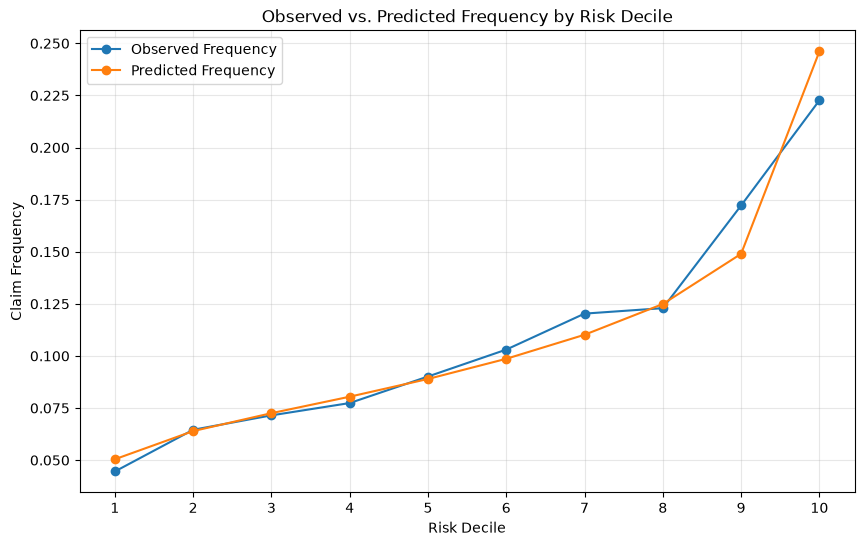

In [24]:
import matplotlib.pyplot as plt


plot_data = frequency_calibration.reset_index()

plt.figure(figsize=(10, 6))

plt.plot(
    plot_data["risk_decile"],
    plot_data["observed_frequency"],
    marker="o",
    label="Observed Frequency",
)

plt.plot(
    plot_data["risk_decile"],
    plot_data["predicted_frequency"],
    marker="o",
    label="Predicted Frequency",
)

plt.xlabel("Risk Decile")
plt.ylabel("Claim Frequency")
plt.title("Observed vs. Predicted Frequency by Risk Decile")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)

plt.show()

**Ergebnis:** Die beobachtete Schadenhäufigkeit steigt über die Risikodezile
deutlich und nahezu monoton an. Das Modell kann somit Policen mit niedriger
und hoher Schadenhäufigkeit sinnvoll unterscheiden.

Die Kalibrierung ist insgesamt plausibel, zeigt jedoch insbesondere in den
höchsten Risikodezilen noch Abweichungen zwischen Beobachtung und Prognose.

## Interpretation des Frequency-Modells

Die geschätzten Koeffizienten des Poisson-Modells werden als relative
Änderungen der erwarteten Schadenhäufigkeit interpretiert.

Für kategoriale Merkmale erfolgt die Interpretation jeweils relativ zur
Referenzkategorie.

In [25]:
fitted_preprocessor = frequency_pipeline.named_steps["preprocessor"]
fitted_encoder = fitted_preprocessor.named_transformers_["categorical"]

print("=== Reference Categories ===")

for feature, categories, drop_idx in zip(
    categorical_features,
    fitted_encoder.categories_,
    fitted_encoder.drop_idx_,
):
    reference = categories[drop_idx]
    print(f"{feature}: {reference}")

=== Reference Categories ===
VehPower: 4
VehBrand: B1
VehGas: Diesel
Region: R11
driver_age_group: 18-24
vehicle_age_group: 0-2
bonus_malus_segment: 100+


### Koeffizienten und Rate Ratios

Zur leichteren Interpretation werden die Modellkoeffizienten exponentiert.

\[
Rate\ Ratio = e^{\beta}
\]

Ein Rate Ratio größer als 1 weist auf eine höhere, ein Wert kleiner als 1
auf eine niedrigere erwartete Schadenhäufigkeit gegenüber der jeweiligen
Referenz hin.

In [26]:
feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

coefficients = poisson_model.coef_

coef_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
})

coef_table["rate_ratio"] = np.exp(
    coef_table["coefficient"]
)

coef_table["feature"] = (
    coef_table["feature"]
    .str.replace("categorical__", "", regex=False)
    .str.replace("numeric__", "", regex=False)
)

coef_table = coef_table.sort_values(
    "rate_ratio",
    ascending=False,
).reset_index(drop=True)

display(coef_table)

,feature,coefficient,rate_ratio
0,VehPower_9,0.273419,1.314451
1,VehPower_10,0.244403,1.276859
2,VehBrand_B12,0.207338,1.230398
3,Region_R74,0.199706,1.221044
4,VehPower_6,0.183308,1.201184
5,Region_R21,0.173660,1.189652
6,Region_R94,0.171170,1.186692
7,Region_R53,0.168636,1.183690
8,VehPower_11,0.163546,1.177679
9,Region_R22,0.158095,1.171278


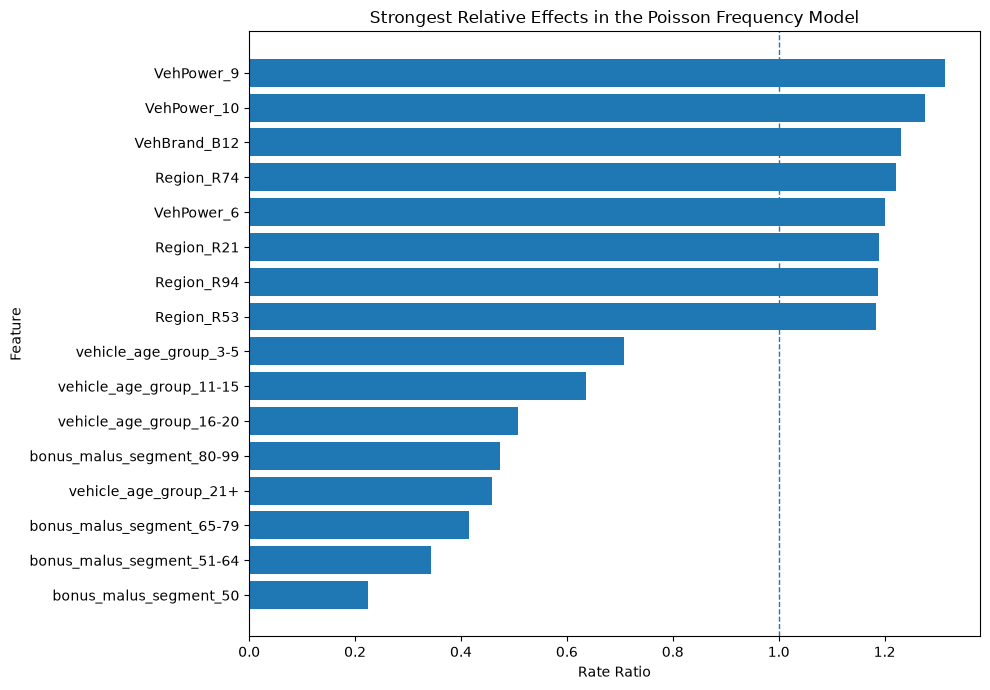

In [27]:
coef_plot = pd.concat([
    coef_table.head(8),
    coef_table.tail(8),
]).sort_values("rate_ratio")

plt.figure(figsize=(10, 7))

plt.barh(
    coef_plot["feature"],
    coef_plot["rate_ratio"],
)

plt.axvline(
    1.0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Rate Ratio")
plt.ylabel("Feature")
plt.title("Strongest Relative Effects in the Poisson Frequency Model")

plt.tight_layout()
plt.show()

**Ergebnis:** Die stärksten relativen Effekte zeigen sich insbesondere bei
Bonus-Malus, Fahrzeugleistung, Fahrzeugalter und einzelnen Regionen.

Die Rate Ratios verdeutlichen deutliche Unterschiede zwischen den
Risikogruppen. Die Effekte sind dabei stets relativ zur jeweiligen
Referenzkategorie und nicht als kausale Zusammenhänge zu interpretieren.

## Cross-Validation und Modelloptimierung

Die Modelloptimierung erfolgt ausschließlich innerhalb des Trainingsdatensatzes.
Dazu wird eine stratifizierte 5-Fold-Cross-Validation verwendet.

Die Stratifizierung basiert auf dem Vorhandensein mindestens eines Schadens,
damit der Anteil schadenbehafteter Policen in den Folds vergleichbar bleibt.
Der Holdout-Testdatensatz wird nicht für die Modellauswahl verwendet.

In [28]:
from sklearn.model_selection import StratifiedKFold


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

cv_stratify = train_df["ClaimNb"].gt(0)

print("=== 5-Fold Cross-Validation Check ===")

for fold, (fit_idx, val_idx) in enumerate(
    cv.split(X_train, cv_stratify),
    start=1,
):
    fold_fit = train_df.iloc[fit_idx]
    fold_val = train_df.iloc[val_idx]

    print(f"\nFold {fold}")
    print(f"  Fit policies:        {len(fold_fit):,}")
    print(f"  Validation policies: {len(fold_val):,}")

    print(
        f"  Fit claim-policy rate: "
        f"{fold_fit['ClaimNb'].gt(0).mean():.4%}"
    )

    print(
        f"  Val claim-policy rate: "
        f"{fold_val['ClaimNb'].gt(0).mean():.4%}"
    )

    print(
        f"  Val frequency: "
        f"{fold_val['ClaimNb'].sum() / fold_val['Exposure'].sum():.6f}"
    )

=== 5-Fold Cross-Validation Check ===

Fold 1
  Fit policies:        433,928
  Validation policies: 108,482
  Fit claim-policy rate: 5.0234%
  Val claim-policy rate: 5.0239%
  Val frequency: 0.100704

Fold 2
  Fit policies:        433,928
  Validation policies: 108,482
  Fit claim-policy rate: 5.0234%
  Val claim-policy rate: 5.0239%
  Val frequency: 0.101292

Fold 3
  Fit policies:        433,928
  Validation policies: 108,482
  Fit claim-policy rate: 5.0234%
  Val claim-policy rate: 5.0239%
  Val frequency: 0.100148

Fold 4
  Fit policies:        433,928
  Validation policies: 108,482
  Fit claim-policy rate: 5.0236%
  Val claim-policy rate: 5.0230%
  Val frequency: 0.100821

Fold 5
  Fit policies:        433,928
  Validation policies: 108,482
  Fit claim-policy rate: 5.0236%
  Val claim-policy rate: 5.0230%
  Val frequency: 0.100323


### Cross-Validation der Regularisierungsstärke

Für die Auswahl der Regularisierungsstärke werden mehrere `alpha`-Werte
innerhalb des Trainingsdatensatzes verglichen.

Bewertet wird die exposure-gewichtete Mean Poisson Deviance der jeweiligen
Validierungsfolds. Ein niedrigerer Wert bedeutet eine bessere Modellgüte.

In [29]:
alpha_values = [
    0.0,
    0.0001,
    0.001,
    0.01,
    0.1,
    1.0,
]

cv_results = []

for alpha in alpha_values:

    fold_deviances = []

    for fold, (fit_idx, val_idx) in enumerate(
        cv.split(X_train, cv_stratify),
        start=1,
    ):
        X_fit = X_train.iloc[fit_idx]
        X_val = X_train.iloc[val_idx]

        y_fit = y_train.iloc[fit_idx]
        y_val = y_train.iloc[val_idx]

        w_fit = w_train.iloc[fit_idx]
        w_val = w_train.iloc[val_idx]

        cv_pipeline = Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    PoissonRegressor(
                        alpha=alpha,
                        max_iter=1000,
                    ),
                ),
            ]
        )

        cv_pipeline.fit(
            X_fit,
            y_fit,
            model__sample_weight=w_fit,
        )

        val_pred = cv_pipeline.predict(X_val)

        fold_deviance = mean_poisson_deviance(
            y_val,
            val_pred,
            sample_weight=w_val,
        )

        fold_deviances.append(fold_deviance)

    cv_results.append({
        "alpha": alpha,
        "mean_poisson_deviance": np.mean(fold_deviances),
        "std_poisson_deviance": np.std(fold_deviances),
    })


cv_results_df = (
    pd.DataFrame(cv_results)
    .sort_values("mean_poisson_deviance")
    .reset_index(drop=True)
)

display(cv_results_df)

,alpha,mean_poisson_deviance,std_poisson_deviance
0,0.0000,0.604616,0.004215
1,0.0001,0.604626,0.004218
2,0.0010,0.606039,0.004220
3,0.0100,0.613049,0.004222
4,0.1000,0.621036,0.004108
5,1.0000,0.625067,0.003934


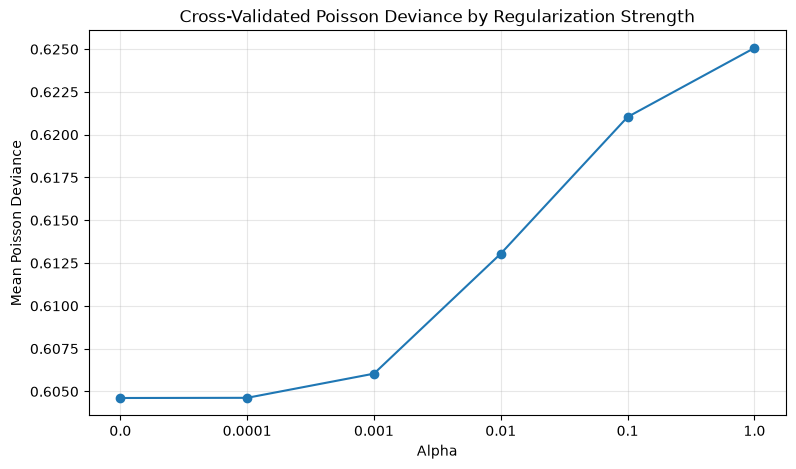

In [30]:
alpha_plot = cv_results_df.sort_values("alpha").copy()
alpha_plot["alpha_label"] = alpha_plot["alpha"].astype(str)

plt.figure(figsize=(9, 5))

plt.plot(
    alpha_plot["alpha_label"],
    alpha_plot["mean_poisson_deviance"],
    marker="o",
)

plt.xlabel("Alpha")
plt.ylabel("Mean Poisson Deviance")
plt.title("Cross-Validated Poisson Deviance by Regularization Strength")
plt.grid(alpha=0.3)

plt.show()

**Ergebnis:** Die niedrigste mittlere Poisson Deviance wird ohne zusätzliche
Regularisierung (`alpha=0`) erreicht. Mit zunehmender Regularisierung
verschlechtert sich die Validierungsleistung.

Für die weitere Modellspezifikation wird daher `alpha=0` beibehalten.

### Vergleich alternativer Feature-Spezifikationen

Zur Verbesserung des Frequency-Modells werden drei unterschiedliche
Darstellungen von Fahrer-Alter, Fahrzeugalter und Bonus-Malus verglichen:

- **Grouped:** Verwendung der aus der EDA abgeleiteten Kategorien.
- **Raw Linear:** Verwendung der ursprünglichen numerischen Variablen.
- **Spline:** Flexible nichtlineare Modellierung der ursprünglichen Variablen.

Alle übrigen Modellmerkmale bleiben unverändert, damit der Einfluss der
jeweiligen Darstellung gezielt beurteilt werden kann.

In [31]:
from sklearn.preprocessing import SplineTransformer


fixed_categorical_features = [
    "VehPower",
    "VehBrand",
    "VehGas",
    "Region",
]

grouped_features = [
    "driver_age_group",
    "vehicle_age_group",
    "bonus_malus_segment",
]

raw_numeric_features = [
    "DrivAge",
    "VehAge",
    "BonusMalus",
]

density_feature = [
    "log_density",
]

In [32]:
# A — Grouped specification
preprocessor_grouped = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
            ),
            fixed_categorical_features + grouped_features,
        ),
        (
            "numeric",
            "passthrough",
            density_feature,
        ),
    ],
    remainder="drop",
)


# B — Raw linear specification
preprocessor_raw = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
            ),
            fixed_categorical_features,
        ),
        (
            "numeric",
            "passthrough",
            raw_numeric_features + density_feature,
        ),
    ],
    remainder="drop",
)


# C — Spline specification
preprocessor_spline = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
            ),
            fixed_categorical_features,
        ),
        (
            "spline",
            SplineTransformer(
                n_knots=5,
                degree=3,
                include_bias=False,
            ),
            raw_numeric_features,
        ),
        (
            "numeric",
            "passthrough",
            density_feature,
        ),
    ],
    remainder="drop",
)

In [33]:
model_specifications = {
    "Grouped": Pipeline(
        steps=[
            ("preprocessor", preprocessor_grouped),
            (
                "model",
                PoissonRegressor(
                    alpha=0.0,
                    max_iter=1000,
                ),
            ),
        ]
    ),

    "Raw Linear": Pipeline(
        steps=[
            ("preprocessor", preprocessor_raw),
            (
                "model",
                PoissonRegressor(
                    alpha=0.0,
                    max_iter=1000,
                ),
            ),
        ]
    ),

    "Spline": Pipeline(
        steps=[
            ("preprocessor", preprocessor_spline),
            (
                "model",
                PoissonRegressor(
                    alpha=0.0,
                    max_iter=1000,
                ),
            ),
        ]
    ),
}

print("Model specifications:")
for name in model_specifications:
    print(f"- {name}")

Model specifications:
- Grouped
- Raw Linear
- Spline


In [34]:
comparison_features = (
    fixed_categorical_features
    + grouped_features
    + raw_numeric_features
    + density_feature
)

X_train_spec = train_df[comparison_features].copy()

print(f"Comparison data shape: {X_train_spec.shape}")
print("\nAvailable features:")
for feature in comparison_features:
    print(f"- {feature}")

Comparison data shape: (542410, 11)

Available features:
- VehPower
- VehBrand
- VehGas
- Region
- driver_age_group
- vehicle_age_group
- bonus_malus_segment
- DrivAge
- VehAge
- BonusMalus
- log_density


### Cross-Validation der Feature-Spezifikationen

Die drei Feature-Spezifikationen werden auf identischen Cross-Validation-Folds
verglichen. Dadurch lässt sich beurteilen, welche Darstellung der Alters- und
Bonus-Malus-Variablen auf unbekannten Trainingsdaten am besten generalisiert.

Als Auswahlkriterium dient die exposure-gewichtete Mean Poisson Deviance.

In [35]:
from sklearn.base import clone


specification_results = []

for model_name, pipeline in model_specifications.items():

    fold_deviances = []

    for fold, (fit_idx, val_idx) in enumerate(
        cv.split(X_train_spec, cv_stratify),
        start=1,
    ):
        X_fit = X_train_spec.iloc[fit_idx]
        X_val = X_train_spec.iloc[val_idx]

        y_fit = y_train.iloc[fit_idx]
        y_val = y_train.iloc[val_idx]

        w_fit = w_train.iloc[fit_idx]
        w_val = w_train.iloc[val_idx]

        fold_pipeline = clone(pipeline)

        fold_pipeline.fit(
            X_fit,
            y_fit,
            model__sample_weight=w_fit,
        )

        val_pred = fold_pipeline.predict(X_val)

        fold_deviance = mean_poisson_deviance(
            y_val,
            val_pred,
            sample_weight=w_val,
        )

        fold_deviances.append(fold_deviance)

    specification_results.append({
        "model": model_name,
        "mean_poisson_deviance": np.mean(fold_deviances),
        "std_poisson_deviance": np.std(fold_deviances),
        "fold_1": fold_deviances[0],
        "fold_2": fold_deviances[1],
        "fold_3": fold_deviances[2],
        "fold_4": fold_deviances[3],
        "fold_5": fold_deviances[4],
    })


specification_results_df = (
    pd.DataFrame(specification_results)
    .sort_values("mean_poisson_deviance")
    .reset_index(drop=True)
)

display(specification_results_df)

,model,mean_poisson_deviance,std_poisson_deviance,fold_1,fold_2,fold_3,fold_4,fold_5
0,Spline,0.602320,0.004235,0.604438,0.608797,0.602442,0.596341,0.599583
1,Grouped,0.604616,0.004215,0.606460,0.611497,0.604228,0.599186,0.601709
2,Raw Linear,0.606130,0.004023,0.607288,0.612481,0.606850,0.600455,0.603574


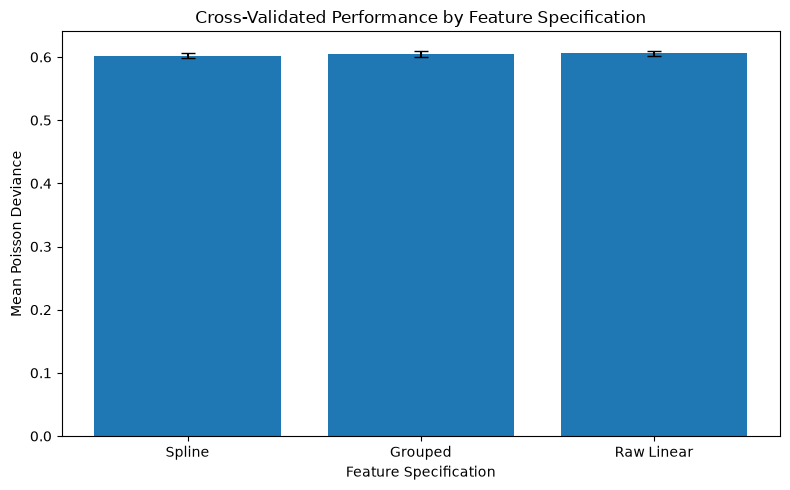

In [36]:
spec_plot = (
    specification_results_df
    .sort_values("mean_poisson_deviance")
    .copy()
)

plt.figure(figsize=(8, 5))

plt.bar(
    spec_plot["model"],
    spec_plot["mean_poisson_deviance"],
    yerr=spec_plot["std_poisson_deviance"],
    capsize=5,
)

plt.ylabel("Mean Poisson Deviance")
plt.xlabel("Feature Specification")
plt.title("Cross-Validated Performance by Feature Specification")

plt.tight_layout()
plt.show()

**Ergebnis:** Die Spline-Spezifikation erzielt die niedrigste mittlere
Poisson Deviance und zeigt in allen fünf Validierungsfolds eine bessere
Leistung als die gruppierte und die rein lineare Spezifikation.

Der Leistungsgewinn ist moderat, aber konsistent. Für die weitere
Optimierung wird daher die Spline-Spezifikation verwendet.

### Optimierung der Spline-Spezifikation

Für die ausgewählte Spline-Spezifikation werden die Anzahl der Knoten,
der Spline-Grad und die Regularisierungsstärke gemeinsam innerhalb der
Trainingsdaten optimiert.

Die Auswahl erfolgt ausschließlich anhand der exposure-gewichteten
Mean Poisson Deviance in der 5-Fold-Cross-Validation.

In [37]:
from itertools import product


n_knots_values = [4, 5, 6]
degree_values = [2, 3]
alpha_values_spline = [0.0, 0.0001, 0.001]

spline_tuning_results = []

for n_knots, degree, alpha in product(
    n_knots_values,
    degree_values,
    alpha_values_spline,
):

    fold_deviances = []

    for fit_idx, val_idx in cv.split(
        X_train_spec,
        cv_stratify,
    ):
        X_fit = X_train_spec.iloc[fit_idx]
        X_val = X_train_spec.iloc[val_idx]

        y_fit = y_train.iloc[fit_idx]
        y_val = y_train.iloc[val_idx]

        w_fit = w_train.iloc[fit_idx]
        w_val = w_train.iloc[val_idx]

        tuning_preprocessor = ColumnTransformer(
            transformers=[
                (
                    "categorical",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        drop="first",
                    ),
                    fixed_categorical_features,
                ),
                (
                    "spline",
                    SplineTransformer(
                        n_knots=n_knots,
                        degree=degree,
                        include_bias=False,
                    ),
                    raw_numeric_features,
                ),
                (
                    "numeric",
                    "passthrough",
                    density_feature,
                ),
            ],
            remainder="drop",
        )

        tuning_pipeline = Pipeline(
            steps=[
                ("preprocessor", tuning_preprocessor),
                (
                    "model",
                    PoissonRegressor(
                        alpha=alpha,
                        max_iter=1000,
                    ),
                ),
            ]
        )

        tuning_pipeline.fit(
            X_fit,
            y_fit,
            model__sample_weight=w_fit,
        )

        val_pred = tuning_pipeline.predict(X_val)

        fold_deviance = mean_poisson_deviance(
            y_val,
            val_pred,
            sample_weight=w_val,
        )

        fold_deviances.append(fold_deviance)

    spline_tuning_results.append({
        "n_knots": n_knots,
        "degree": degree,
        "alpha": alpha,
        "mean_poisson_deviance": np.mean(fold_deviances),
        "std_poisson_deviance": np.std(fold_deviances),
    })


spline_tuning_df = (
    pd.DataFrame(spline_tuning_results)
    .sort_values(
        ["mean_poisson_deviance", "std_poisson_deviance"]
    )
    .reset_index(drop=True)
)

display(spline_tuning_df)

,n_knots,degree,alpha,mean_poisson_deviance,std_poisson_deviance
0,6,3,0.0000,0.601486,0.004282
1,5,3,0.0000,0.602320,0.004235
2,6,2,0.0000,0.603572,0.004227
3,6,2,0.0001,0.603652,0.004181
4,4,3,0.0000,0.603836,0.004450
5,5,2,0.0000,0.604248,0.004207
6,6,3,0.0001,0.604257,0.004137
7,5,2,0.0001,0.604319,0.004145
8,5,3,0.0001,0.605118,0.004023
9,4,2,0.0000,0.605350,0.004026


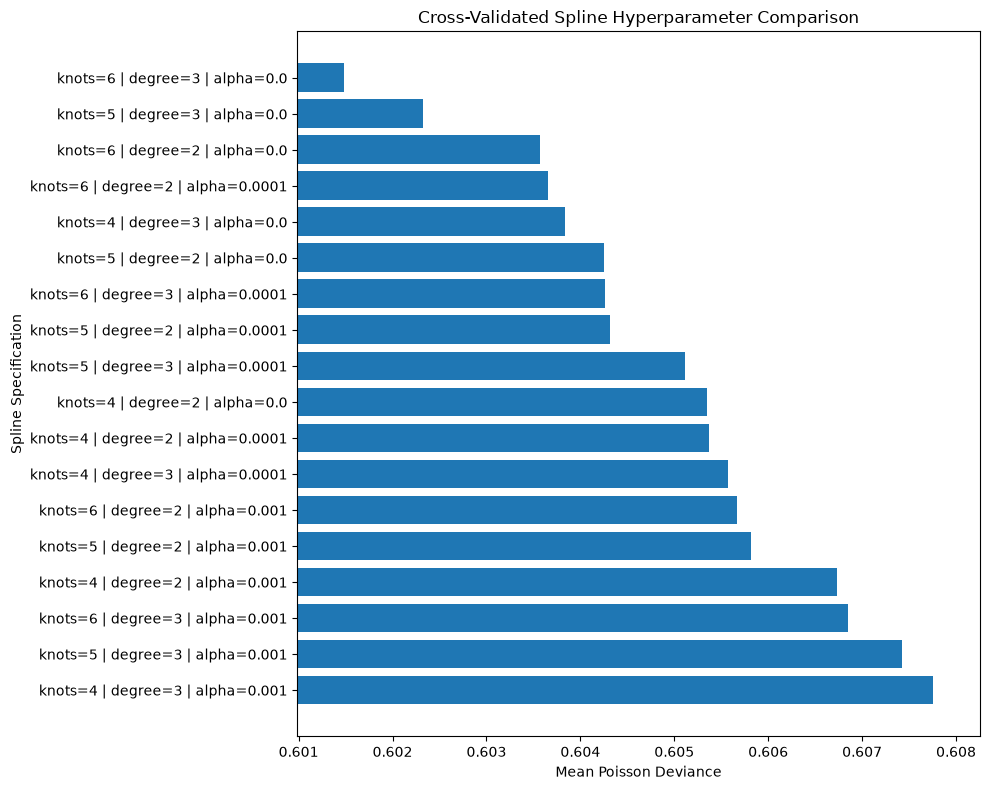

In [38]:
tuning_plot = spline_tuning_df.copy()

tuning_plot["specification"] = (
    "knots=" + tuning_plot["n_knots"].astype(str)
    + " | degree=" + tuning_plot["degree"].astype(str)
    + " | alpha=" + tuning_plot["alpha"].astype(str)
)

tuning_plot = tuning_plot.sort_values(
    "mean_poisson_deviance",
    ascending=False,
)

plt.figure(figsize=(10, 8))

plt.barh(
    tuning_plot["specification"],
    tuning_plot["mean_poisson_deviance"],
)

plt.xlabel("Mean Poisson Deviance")
plt.ylabel("Spline Specification")
plt.title("Cross-Validated Spline Hyperparameter Comparison")

plt.xlim(
    tuning_plot["mean_poisson_deviance"].min() - 0.0005,
    tuning_plot["mean_poisson_deviance"].max() + 0.0005,
)

plt.tight_layout()
plt.show()

**Ergebnis:** Die beste Cross-Validation-Leistung erzielt die Spline-
Spezifikation mit sechs Knoten, Grad 3 und ohne Regularisierung
(`alpha=0`).

Die Unterschiede zwischen den besten Spezifikationen sind moderat, jedoch
zeigt die gewählte Konfiguration die niedrigste mittlere Poisson Deviance.

## Finales Frequency-Modell

Auf Basis der Cross-Validation wird die finale Poisson-Spezifikation mit
sechs Spline-Knoten, Grad 3 und ohne zusätzliche Regularisierung festgelegt.

Das Modell wird nun auf dem vollständigen Trainingsdatensatz geschätzt und
anschließend einmalig auf dem Holdout-Testdatensatz bewertet.

In [39]:
final_frequency_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
            ),
            fixed_categorical_features,
        ),
        (
            "spline",
            SplineTransformer(
                n_knots=6,
                degree=3,
                include_bias=False,
            ),
            raw_numeric_features,
        ),
        (
            "numeric",
            "passthrough",
            density_feature,
        ),
    ],
    remainder="drop",
)

final_frequency_pipeline = Pipeline(
    steps=[
        ("preprocessor", final_frequency_preprocessor),
        (
            "model",
            PoissonRegressor(
                alpha=0.0,
                max_iter=1000,
            ),
        ),
    ]
)

final_frequency_pipeline.fit(
    X_train_spec,
    y_train,
    model__sample_weight=w_train,
)

print("Final Poisson frequency model fitted successfully.")

Final Poisson frequency model fitted successfully.


### Finale Prognosen auf dem Holdout-Testdatensatz

Nach Abschluss der Modellauswahl werden mit der festgelegten
Modellspezifikation Prognosen für den Holdout-Testdatensatz erzeugt.

Vor der finalen Bewertung werden die Vorhersagen nochmals technisch geprüft.

In [40]:
X_test_spec = test_df[comparison_features].copy()

final_y_pred_test = final_frequency_pipeline.predict(
    X_test_spec
)

final_poisson_model = (
    final_frequency_pipeline
    .named_steps["model"]
)

print("=== Final Prediction Sanity Check ===")
print(f"Predictions:          {len(final_y_pred_test):,}")
print(f"NaN predictions:      {np.isnan(final_y_pred_test).sum():,}")
print(f"Infinite predictions: {np.isinf(final_y_pred_test).sum():,}")
print(f"Non-positive preds:   {(final_y_pred_test <= 0).sum():,}")

print("\n=== Prediction Range ===")
print(f"Minimum: {final_y_pred_test.min():.6f}")
print(f"Mean:    {final_y_pred_test.mean():.6f}")
print(f"Median:  {np.median(final_y_pred_test):.6f}")
print(f"Maximum: {final_y_pred_test.max():.6f}")

print("\n=== Optimizer ===")
print(f"Iterations used: {final_poisson_model.n_iter_}")

=== Final Prediction Sanity Check ===
Predictions:          135,603
NaN predictions:      0
Infinite predictions: 0
Non-positive preds:   0

=== Prediction Range ===
Minimum: 0.004206
Mean:    0.109602
Median:  0.093861
Maximum: 1.352795

=== Optimizer ===
Iterations used: 179


### Finale Bewertung des Frequency-Modells

Die finale Modellleistung wird auf dem unangetasteten Holdout-Testdatensatz
bewertet. Neben der Mean Poisson Deviance werden die Verbesserung gegenüber
dem Baseline-Modell, der Poisson-D²-Score sowie exposure-korrekte
Portfoliokennzahlen berichtet.

In [41]:
from sklearn.metrics import d2_tweedie_score


final_poisson_deviance = mean_poisson_deviance(
    y_test,
    final_y_pred_test,
    sample_weight=w_test,
)

final_d2_poisson = d2_tweedie_score(
    y_test,
    final_y_pred_test,
    sample_weight=w_test,
    power=1,
)

improvement_vs_baseline = (
    (baseline_deviance - final_poisson_deviance)
    / baseline_deviance
)

final_predicted_claims = (
    final_y_pred_test * w_test.to_numpy()
).sum()

final_actual_claims = test_df["ClaimNb"].sum()

final_actual_frequency = (
    final_actual_claims / w_test.sum()
)

final_predicted_frequency = (
    final_predicted_claims / w_test.sum()
)

claim_difference = (
    final_predicted_claims - final_actual_claims
)

claim_difference_pct = (
    claim_difference / final_actual_claims
)


print("=== Final Holdout Evaluation ===")
print(f"Baseline Mean Poisson Deviance: {baseline_deviance:.6f}")
print(f"Final Mean Poisson Deviance:    {final_poisson_deviance:.6f}")
print(f"Improvement vs baseline:        {improvement_vs_baseline:.2%}")
print(f"Poisson D²:                     {final_d2_poisson:.4f}")

print("\n=== Exposure-Weighted Portfolio Validation ===")
print(f"Actual claims:                  {final_actual_claims:,.0f}")
print(f"Predicted claims:               {final_predicted_claims:,.2f}")
print(f"Difference:                     {claim_difference:,.2f}")
print(f"Difference %:                   {claim_difference_pct:.2%}")

print(f"\nActual frequency:               {final_actual_frequency:.6f}")
print(f"Predicted frequency:            {final_predicted_frequency:.6f}")

=== Final Holdout Evaluation ===
Baseline Mean Poisson Deviance: 0.625748
Final Mean Poisson Deviance:    0.601319
Improvement vs baseline:        3.90%
Poisson D²:                     0.0390

=== Exposure-Weighted Portfolio Validation ===
Actual claims:                  7,236
Predicted claims:               7,211.98
Difference:                     -24.02
Difference %:                   -0.33%

Actual frequency:               0.101085
Predicted frequency:            0.100749


### Finale Kalibrierung nach Risikodezilen

Die finale Spline-Spezifikation wird zusätzlich auf ihre Risikodifferenzierung
und Kalibrierung untersucht. Dazu werden die Testpolicen anhand der finalen
prognostizierten Schadenhäufigkeit in zehn gleich große Risikogruppen eingeteilt.

Beobachtete und prognostizierte Schadenhäufigkeiten werden exposure-korrekt
aggregiert.

In [42]:
final_frequency_eval = test_df[
    ["IDpol", "ClaimNb", "Exposure"]
].copy()

final_frequency_eval["predicted_frequency"] = final_y_pred_test

final_frequency_eval["risk_decile"] = pd.qcut(
    final_frequency_eval["predicted_frequency"],
    q=10,
    labels=False,
    duplicates="drop",
) + 1

final_frequency_eval["predicted_claims"] = (
    final_frequency_eval["predicted_frequency"]
    * final_frequency_eval["Exposure"]
)

final_frequency_calibration = (
    final_frequency_eval
    .groupby("risk_decile", observed=True)
    .agg(
        policies=("IDpol", "size"),
        exposure=("Exposure", "sum"),
        actual_claims=("ClaimNb", "sum"),
        predicted_claims=("predicted_claims", "sum"),
    )
)

final_frequency_calibration["observed_frequency"] = (
    final_frequency_calibration["actual_claims"]
    / final_frequency_calibration["exposure"]
)

final_frequency_calibration["predicted_frequency"] = (
    final_frequency_calibration["predicted_claims"]
    / final_frequency_calibration["exposure"]
)

display(final_frequency_calibration)

,policies,exposure,actual_claims,predicted_claims,observed_frequency,predicted_frequency
risk_decile,,,,,,
1,13561,8742.954592,383,420.449308,0.043807,0.048090
2,13560,8684.830084,578,537.078294,0.066553,0.061841
3,13560,8457.412642,599,596.819190,0.070825,0.070568
4,13560,8151.319787,620,644.556201,0.076061,0.079074
5,13561,7463.916843,659,661.088018,0.088291,0.088571
6,13560,6834.385944,641,680.143548,0.093790,0.099518
7,13560,6421.739030,703,720.669652,0.109472,0.112223
8,13560,6012.700240,788,773.536519,0.131056,0.128650
9,13560,5605.874185,951,865.182227,0.169643,0.154335


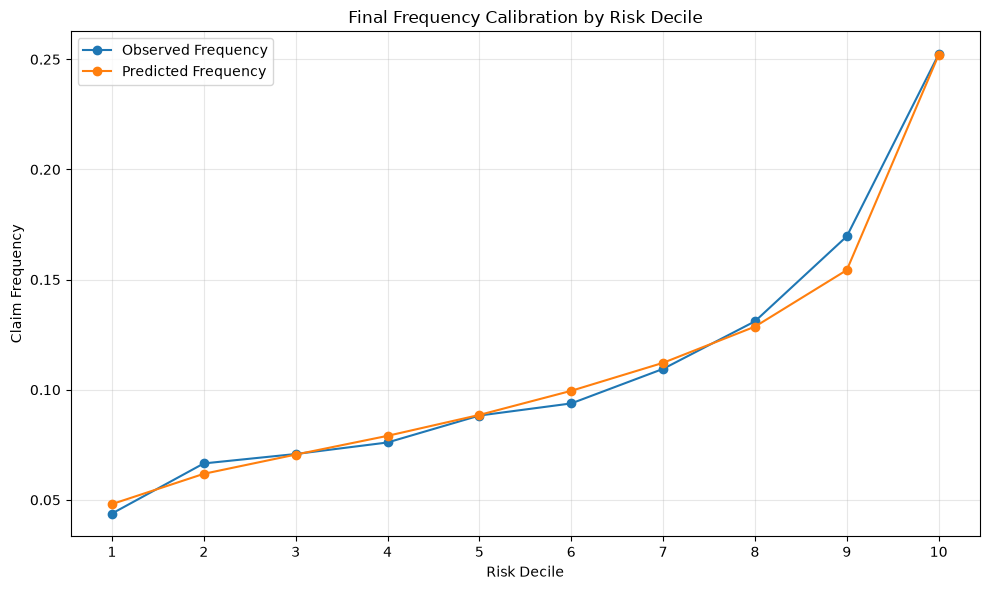

In [43]:
final_calibration_plot = (
    final_frequency_calibration
    .reset_index()
)

plt.figure(figsize=(10, 6))

plt.plot(
    final_calibration_plot["risk_decile"],
    final_calibration_plot["observed_frequency"],
    marker="o",
    label="Observed Frequency",
)

plt.plot(
    final_calibration_plot["risk_decile"],
    final_calibration_plot["predicted_frequency"],
    marker="o",
    label="Predicted Frequency",
)

plt.xlabel("Risk Decile")
plt.ylabel("Claim Frequency")
plt.title("Final Frequency Calibration by Risk Decile")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Ergebnis:** Das finale Frequency-Modell zeigt über die Risikodezile eine
klare und monotone Trennung der beobachteten Schadenhäufigkeit.

Beobachtete und prognostizierte Frequenzen liegen insgesamt nah beieinander.
Größere Abweichungen treten nur in einzelnen Risikogruppen auf, während
insbesondere das höchste Risikodezil sehr gut kalibriert ist.

## Speicherung des evaluierten Modellartefakts

Die nach Cross-Validation festgelegte Frequency-Pipeline wird als
reproduzierbares Modellartefakt gespeichert.

Dieses Artefakt wurde ausschließlich auf dem Trainingsdatensatz geschätzt.
Ein späterer Refit auf dem vollständigen Portfolio wird davon klar getrennt.

In [44]:
import joblib


MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

FREQUENCY_MODEL_PATH = (
    MODEL_DIR
    / "frequency_poisson_spline_holdout_v1.joblib"
)

joblib.dump(
    final_frequency_pipeline,
    FREQUENCY_MODEL_PATH,
)

print(f"Saved model: {FREQUENCY_MODEL_PATH}")
print(f"Exists:      {FREQUENCY_MODEL_PATH.exists()}")
print(
    f"Size:        "
    f"{FREQUENCY_MODEL_PATH.stat().st_size / 1024:.2f} KB"
)

Saved model: c:\Users\Mesut\Desktop\kfz-insurance-risk-platform\models\frequency_poisson_spline_holdout_v1.joblib
Exists:      True
Size:        7.84 KB


In [45]:
loaded_frequency_pipeline = joblib.load(
    FREQUENCY_MODEL_PATH
)

reloaded_y_pred_test = loaded_frequency_pipeline.predict(
    X_test_spec
)

predictions_identical = np.array_equal(
    final_y_pred_test,
    reloaded_y_pred_test,
)

max_absolute_difference = np.max(
    np.abs(final_y_pred_test - reloaded_y_pred_test)
)

print("=== Model Artifact Validation ===")
print(f"Predictions:              {len(reloaded_y_pred_test):,}")
print(f"Predictions identical:    {predictions_identical}")
print(f"Maximum absolute diff.:   {max_absolute_difference:.12f}")

=== Model Artifact Validation ===
Predictions:              135,603
Predictions identical:    True
Maximum absolute diff.:   0.000000000000


**Ergebnis:** Das evaluierte Frequency-Modell wurde erfolgreich als
reproduzierbares Pipeline-Artefakt gespeichert und erneut geladen.

Die Vorhersagen des gespeicherten Modells stimmen exakt mit den
ursprünglichen Holdout-Prognosen überein.

## Post-Audit-Validierung der Frequency-Spezifikation

Die bisherige Frequency-Spezifikation verwendet standardmäßig gleichmäßig
über den Wertebereich verteilte Spline-Knoten (`knots="uniform"`).

Da insbesondere `BonusMalus` und `VehAge` stark ungleich verteilt sind,
wird geprüft, ob quantilbasierte Knoten die Datenstruktur besser abbilden.

Die Spezifikationen werden ausschließlich auf den Trainingsdaten mit
wiederholter Cross-Validation verglichen. Der Holdout-Datensatz wird für
diese Modellauswahl nicht verwendet.

In [46]:
frequency_cv_seeds = [
    42,
    7,
    123,
    2024,
    99,
]

frequency_knot_results = []


def make_frequency_knot_pipeline(
    knot_strategy: str,
) -> Pipeline:
    """Build the Frequency pipeline for a given knot strategy."""

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    drop="first",
                ),
                fixed_categorical_features,
            ),
            (
                "spline",
                SplineTransformer(
                    n_knots=6,
                    degree=3,
                    knots=knot_strategy,
                    include_bias=False,
                ),
                raw_numeric_features,
            ),
            (
                "numeric",
                "passthrough",
                density_feature,
            ),
        ],
        remainder="drop",
    )

    return Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor,
            ),
            (
                "model",
                PoissonRegressor(
                    alpha=0.0,
                    max_iter=1000,
                ),
            ),
        ]
    )


for seed in frequency_cv_seeds:

    cv_repeated = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed,
    )

    cv_splits = list(
        cv_repeated.split(
            X_train_spec,
            cv_stratify,
        )
    )

    for knot_strategy in [
        "uniform",
        "quantile",
    ]:

        oof_pred = np.empty(
            len(X_train_spec),
            dtype=float,
        )

        fold_deviances = []
        fold_iterations = []

        for fit_idx, val_idx in cv_splits:

            X_fit = X_train_spec.iloc[fit_idx]
            X_val = X_train_spec.iloc[val_idx]

            y_fit = y_train.iloc[fit_idx]
            y_val = y_train.iloc[val_idx]

            w_fit = w_train.iloc[fit_idx]
            w_val = w_train.iloc[val_idx]

            pipeline = make_frequency_knot_pipeline(
                knot_strategy
            )

            pipeline.fit(
                X_fit,
                y_fit,
                model__sample_weight=w_fit,
            )

            val_pred = pipeline.predict(
                X_val
            )

            oof_pred[val_idx] = val_pred

            fold_deviances.append(
                mean_poisson_deviance(
                    y_val,
                    val_pred,
                    sample_weight=w_val,
                )
            )

            fold_iterations.append(
                pipeline
                .named_steps["model"]
                .n_iter_
            )

        pooled_deviance = (
            mean_poisson_deviance(
                y_train,
                oof_pred,
                sample_weight=w_train,
            )
        )

        frequency_knot_results.append({
            "seed": seed,
            "knots": knot_strategy,
            "pooled_deviance": (
                pooled_deviance
            ),
            "mean_fold_deviance": np.mean(
                fold_deviances
            ),
            "std_fold_deviance": np.std(
                fold_deviances,
                ddof=1,
            ),
            "max_iterations": max(
                fold_iterations
            ),
        })


frequency_knot_results_df = pd.DataFrame(
    frequency_knot_results
)

frequency_knot_summary = (
    frequency_knot_results_df
    .groupby(
        "knots",
        as_index=False,
    )
    .agg(
        mean_pooled_deviance=(
            "pooled_deviance",
            "mean",
        ),
        std_pooled_deviance=(
            "pooled_deviance",
            "std",
        ),
        min_pooled_deviance=(
            "pooled_deviance",
            "min",
        ),
        max_pooled_deviance=(
            "pooled_deviance",
            "max",
        ),
        max_iterations=(
            "max_iterations",
            "max",
        ),
    )
    .sort_values(
        "mean_pooled_deviance"
    )
    .reset_index(drop=True)
)

display(frequency_knot_summary)


paired_knot_results = (
    frequency_knot_results_df
    .pivot(
        index="seed",
        columns="knots",
        values="pooled_deviance",
    )
    .reset_index()
)

paired_knot_results[
    "quantile_beats_uniform"
] = (
    paired_knot_results["quantile"]
    < paired_knot_results["uniform"]
)

display(paired_knot_results)


print("\n=== Frequency Knot Strategy Summary ===")

print(
    "Uniform mean:  "
    f"{paired_knot_results['uniform'].mean():.6f}"
)

print(
    "Quantile mean: "
    f"{paired_knot_results['quantile'].mean():.6f}"
)

print(
    "Quantile wins: "
    f"{paired_knot_results['quantile_beats_uniform'].sum()} / "
    f"{len(frequency_cv_seeds)} seeds"
)

,knots,mean_pooled_deviance,std_pooled_deviance,min_pooled_deviance,max_pooled_deviance,max_iterations
0,quantile,0.593385,0.000036,0.593353,0.593445,169
1,uniform,0.601429,0.000055,0.601372,0.601486,322


knots,seed,quantile,uniform,quantile_beats_uniform
0,7,0.593390,0.601486,True
1,42,0.593365,0.601479,True
2,99,0.593445,0.601435,True
3,123,0.593373,0.601373,True
4,2024,0.593353,0.601372,True



=== Frequency Knot Strategy Summary ===
Uniform mean:  0.601429
Quantile mean: 0.593385
Quantile wins: 5 / 5 seeds


### Ergebnis

Die quantilbasierte Platzierung der Spline-Knoten verbessert die
Frequency-Modellierung deutlich und stabil.

Die mittlere gepoolte OOF-Poisson-Deviance sinkt von **0,6014** bei
gleichmäßig verteilten Knoten auf **0,5934** bei quantilbasierten Knoten.
Die Quantil-Spezifikation gewinnt in **allen fünf Wiederholungen**.

Damit bestätigt sich, dass die stark ungleich verteilten numerischen
Merkmale durch datenadaptive Knoten besser abgebildet werden. Gleichzeitig
benötigt die Quantil-Spezifikation deutlich weniger Optimierungsiterationen.

Für die weitere Modellauswahl wird daher ausschließlich die
Quantil-Spline-Spezifikation verwendet. Der Holdout bleibt weiterhin
unberührt.

In [47]:
frequency_quantile_grid_results = []

frequency_n_knots_grid = [
    4,
    5,
    6,
    8,
]

frequency_degree_grid = [
    2,
    3,
]

frequency_alpha_grid = [
    0.0,
    0.0001,
    0.001,
    0.01,
    0.1,
]


for n_knots in frequency_n_knots_grid:
    for degree in frequency_degree_grid:
        for alpha in frequency_alpha_grid:

            seed_deviances = []

            for seed in frequency_cv_seeds:

                cv = StratifiedKFold(
                    n_splits=5,
                    shuffle=True,
                    random_state=seed,
                )

                oof_pred = np.empty(
                    len(X_train_spec),
                    dtype=float,
                )

                for fit_idx, val_idx in cv.split(
                    X_train_spec,
                    cv_stratify,
                ):
                    X_fit = X_train_spec.iloc[fit_idx]
                    X_val = X_train_spec.iloc[val_idx]

                    y_fit = y_train.iloc[fit_idx]
                    w_fit = w_train.iloc[fit_idx]

                    preprocessor = ColumnTransformer(
                        transformers=[
                            (
                                "categorical",
                                OneHotEncoder(
                                    handle_unknown="ignore",
                                    drop="first",
                                ),
                                fixed_categorical_features,
                            ),
                            (
                                "spline",
                                SplineTransformer(
                                    n_knots=n_knots,
                                    degree=degree,
                                    knots="quantile",
                                    include_bias=False,
                                ),
                                raw_numeric_features,
                            ),
                            (
                                "numeric",
                                "passthrough",
                                density_feature,
                            ),
                        ],
                        remainder="drop",
                    )

                    pipeline = Pipeline(
                        steps=[
                            (
                                "preprocessor",
                                preprocessor,
                            ),
                            (
                                "model",
                                PoissonRegressor(
                                    alpha=alpha,
                                    max_iter=1500,
                                ),
                            ),
                        ]
                    )

                    pipeline.fit(
                        X_fit,
                        y_fit,
                        model__sample_weight=w_fit,
                    )

                    oof_pred[val_idx] = (
                        pipeline.predict(
                            X_val
                        )
                    )

                pooled_deviance = (
                    mean_poisson_deviance(
                        y_train,
                        oof_pred,
                        sample_weight=w_train,
                    )
                )

                seed_deviances.append(
                    pooled_deviance
                )

            frequency_quantile_grid_results.append({
                "n_knots": n_knots,
                "degree": degree,
                "alpha": alpha,
                "mean_pooled_deviance": np.mean(
                    seed_deviances
                ),
                "std_pooled_deviance": np.std(
                    seed_deviances,
                    ddof=1,
                ),
                "min_pooled_deviance": np.min(
                    seed_deviances
                ),
                "max_pooled_deviance": np.max(
                    seed_deviances
                ),
            })


frequency_quantile_grid_df = (
    pd.DataFrame(
        frequency_quantile_grid_results
    )
    .sort_values(
        "mean_pooled_deviance"
    )
    .reset_index(drop=True)
)

display(
    frequency_quantile_grid_df.head(15)
)

best_frequency_quantile = (
    frequency_quantile_grid_df.iloc[0]
)

print(
    "\n=== Best Quantile Frequency Specification ==="
)

print(
    f"n_knots:                "
    f"{int(best_frequency_quantile['n_knots'])}"
)

print(
    f"degree:                 "
    f"{int(best_frequency_quantile['degree'])}"
)

print(
    f"alpha:                  "
    f"{best_frequency_quantile['alpha']}"
)

print(
    f"Mean pooled deviance:   "
    f"{best_frequency_quantile['mean_pooled_deviance']:.6f}"
)

print(
    f"Std pooled deviance:    "
    f"{best_frequency_quantile['std_pooled_deviance']:.6f}"
)

,n_knots,degree,alpha,mean_pooled_deviance,std_pooled_deviance,min_pooled_deviance,max_pooled_deviance
0,8,2,0.0000,0.592944,0.000034,0.592888,0.592979
1,8,2,0.0001,0.593125,0.000036,0.593067,0.593163
2,8,3,0.0000,0.593306,0.000078,0.593221,0.593433
3,6,3,0.0000,0.593385,0.000036,0.593353,0.593445
4,5,3,0.0000,0.593414,0.000069,0.593311,0.593473
5,6,2,0.0000,0.594139,0.000032,0.594087,0.594167
6,8,3,0.0001,0.594221,0.000030,0.594179,0.594254
7,4,3,0.0000,0.594231,0.000041,0.594185,0.594272
8,6,2,0.0001,0.594339,0.000037,0.594283,0.594382
9,5,2,0.0000,0.594378,0.000032,0.594343,0.594426



=== Best Quantile Frequency Specification ===
n_knots:                8
degree:                 2
alpha:                  0.0
Mean pooled deviance:   0.592944
Std pooled deviance:    0.000034


### Ergebnis

Die erneute Hyperparameter-Suche auf Basis quantilbasierter Spline-Knoten
identifiziert **8 Knoten**, **Grad 2** und **alpha = 0,0** als beste
Frequency-Spezifikation.

Die mittlere gepoolte OOF-Poisson-Deviance beträgt **0,592944** bei einer
sehr geringen Streuung von **0,000034** über die fünf Wiederholungen.

Gegenüber der bisherigen Uniform-Spline-Spezifikation verbessert sich die
Cross-Validation damit nochmals deutlich. Die Modellauswahl basiert weiterhin
ausschließlich auf den Trainingsdaten.

## Nichtlinearität von `log_density`

Abschließend wird geprüft, ob die Bevölkerungsdichte zusätzlich nichtlinear
modelliert werden sollte.

Die bereits ausgewählte Quantil-Spline-Spezifikation für `DrivAge`,
`VehAge` und `BonusMalus` bleibt unverändert. Verglichen werden lediglich
eine lineare Behandlung von `log_density` und zwei kompakte
Spline-Varianten.

Auch diese Entscheidung erfolgt ausschließlich anhand der Trainingsdaten.

In [48]:
frequency_density_results = []

density_specs = [
    ("linear", None),
    ("spline_4", 4),
    ("spline_6", 6),
]


def make_frequency_density_pipeline(
    density_n_knots=None,
):
    transformers = [
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
            ),
            fixed_categorical_features,
        ),
        (
            "spline",
            SplineTransformer(
                n_knots=8,
                degree=2,
                knots="quantile",
                include_bias=False,
            ),
            raw_numeric_features,
        ),
    ]

    if density_n_knots is None:
        transformers.append(
            (
                "density",
                "passthrough",
                density_feature,
            )
        )
    else:
        transformers.append(
            (
                "density",
                SplineTransformer(
                    n_knots=density_n_knots,
                    degree=2,
                    knots="quantile",
                    include_bias=False,
                ),
                density_feature,
            )
        )

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop",
    )

    return Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor,
            ),
            (
                "model",
                PoissonRegressor(
                    alpha=0.0,
                    max_iter=1500,
                ),
            ),
        ]
    )


for seed in frequency_cv_seeds:

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed,
    )

    cv_splits = list(
        cv.split(
            X_train_spec,
            cv_stratify,
        )
    )

    for density_name, density_n_knots in density_specs:

        oof_pred = np.empty(
            len(X_train_spec),
            dtype=float,
        )

        for fit_idx, val_idx in cv_splits:

            X_fit = X_train_spec.iloc[fit_idx]
            X_val = X_train_spec.iloc[val_idx]

            y_fit = y_train.iloc[fit_idx]
            w_fit = w_train.iloc[fit_idx]

            pipeline = make_frequency_density_pipeline(
                density_n_knots
            )

            pipeline.fit(
                X_fit,
                y_fit,
                model__sample_weight=w_fit,
            )

            oof_pred[val_idx] = pipeline.predict(
                X_val
            )

        pooled_deviance = mean_poisson_deviance(
            y_train,
            oof_pred,
            sample_weight=w_train,
        )

        frequency_density_results.append({
            "seed": seed,
            "density_spec": density_name,
            "pooled_deviance": pooled_deviance,
        })


frequency_density_results_df = pd.DataFrame(
    frequency_density_results
)

frequency_density_summary = (
    frequency_density_results_df
    .groupby(
        "density_spec",
        as_index=False,
    )
    .agg(
        mean_pooled_deviance=(
            "pooled_deviance",
            "mean",
        ),
        std_pooled_deviance=(
            "pooled_deviance",
            "std",
        ),
        min_pooled_deviance=(
            "pooled_deviance",
            "min",
        ),
        max_pooled_deviance=(
            "pooled_deviance",
            "max",
        ),
    )
    .sort_values(
        "mean_pooled_deviance"
    )
    .reset_index(drop=True)
)

display(frequency_density_summary)

best_density_spec = (
    frequency_density_summary.iloc[0]
)

print(
    "\n=== Frequency Density Specification ==="
)

print(
    f"Best density treatment:  "
    f"{best_density_spec['density_spec']}"
)

print(
    f"Mean pooled deviance:     "
    f"{best_density_spec['mean_pooled_deviance']:.6f}"
)

print(
    f"Std pooled deviance:      "
    f"{best_density_spec['std_pooled_deviance']:.6f}"
)

,density_spec,mean_pooled_deviance,std_pooled_deviance,min_pooled_deviance,max_pooled_deviance
0,linear,0.592944,0.000034,0.592888,0.592979
1,spline_6,0.592954,0.000046,0.592892,0.593015
2,spline_4,0.592977,0.000049,0.592913,0.593039



=== Frequency Density Specification ===
Best density treatment:  linear
Mean pooled deviance:     0.592944
Std pooled deviance:      0.000034


### Ergebnis

Eine nichtlineare Modellierung von `log_density` liefert keinen zusätzlichen
Nutzen.

Die lineare Spezifikation erreicht mit **0,592944** die niedrigste mittlere
gepoolte OOF-Poisson-Deviance. Die Spline-Varianten mit vier bzw. sechs
Knoten liegen geringfügig darüber.

Aufgrund der besseren Performance und der geringeren Modellkomplexität
bleibt `log_density` daher linear.

Damit ist die Frequency-v2-Spezifikation auf Basis der Trainingsdaten
festgelegt.

## Holdout-Bestätigung der Frequency-v2-Spezifikation

Die finale Frequency-v2-Spezifikation wurde ausschließlich anhand der
Trainingsdaten und der wiederholten Cross-Validation ausgewählt.

Sie verwendet quantilbasierte Splines mit **8 Knoten und Grad 2** für
`DrivAge`, `VehAge` und `BonusMalus`, während `log_density` linear bleibt.
Eine Regularisierung wird nicht verwendet (`alpha = 0,0`).

Der Holdout wurde bereits während der ursprünglichen Frequency-v1-
Entwicklung betrachtet. Die Post-Audit-Spezifikation wurde jedoch nicht
anhand der Holdout-Ergebnisse ausgewählt. Die folgende Auswertung dient
daher ausschließlich der Bestätigung der Generalisierung.

In [49]:
final_frequency_v2_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
            ),
            fixed_categorical_features,
        ),
        (
            "spline",
            SplineTransformer(
                n_knots=8,
                degree=2,
                knots="quantile",
                include_bias=False,
            ),
            raw_numeric_features,
        ),
        (
            "numeric",
            "passthrough",
            density_feature,
        ),
    ],
    remainder="drop",
)

final_frequency_v2_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            final_frequency_v2_preprocessor,
        ),
        (
            "model",
            PoissonRegressor(
                alpha=0.0,
                max_iter=1500,
            ),
        ),
    ]
)

final_frequency_v2_pipeline.fit(
    X_train_spec,
    y_train,
    model__sample_weight=w_train,
)

frequency_v2_test_pred = (
    final_frequency_v2_pipeline.predict(
        X_test_spec
    )
)

frequency_v2_test_deviance = (
    mean_poisson_deviance(
        y_test,
        frequency_v2_test_pred,
        sample_weight=w_test,
    )
)

frequency_v2_d2 = d2_tweedie_score(
    y_test,
    frequency_v2_test_pred,
    sample_weight=w_test,
    power=1,
)

frequency_v2_predicted_claims = np.sum(
    frequency_v2_test_pred
    * w_test.to_numpy()
)

frequency_v2_actual_claims = (
    test_df["ClaimNb"].sum()
)

frequency_v2_claim_difference = (
    frequency_v2_predicted_claims
    - frequency_v2_actual_claims
)

frequency_v2_claim_difference_pct = (
    frequency_v2_claim_difference
    / frequency_v2_actual_claims
)

frequency_v2_actual_frequency = (
    frequency_v2_actual_claims
    / w_test.sum()
)

frequency_v2_predicted_frequency = (
    frequency_v2_predicted_claims
    / w_test.sum()
)

frequency_v2_improvement_vs_baseline = (
    (
        baseline_deviance
        - frequency_v2_test_deviance
    )
    / baseline_deviance
)

frequency_v2_improvement_vs_v1 = (
    (
        final_poisson_deviance
        - frequency_v2_test_deviance
    )
    / final_poisson_deviance
)

print(
    "=== Frequency v2 — Holdout Confirmation ==="
)

print(
    f"Baseline Poisson Deviance:     "
    f"{baseline_deviance:.6f}"
)

print(
    f"Frequency v1 Deviance:         "
    f"{final_poisson_deviance:.6f}"
)

print(
    f"Frequency v2 Deviance:         "
    f"{frequency_v2_test_deviance:.6f}"
)

print(
    f"Improvement vs baseline:       "
    f"{frequency_v2_improvement_vs_baseline:.2%}"
)

print(
    f"Improvement vs Frequency v1:   "
    f"{frequency_v2_improvement_vs_v1:.2%}"
)

print(
    f"Frequency v2 D²:               "
    f"{frequency_v2_d2:.4f}"
)

print(
    "\n=== Exposure-Weighted Portfolio Validation ==="
)

print(
    f"Actual claims:                 "
    f"{frequency_v2_actual_claims:,.0f}"
)

print(
    f"Predicted claims:              "
    f"{frequency_v2_predicted_claims:,.2f}"
)

print(
    f"Difference:                    "
    f"{frequency_v2_claim_difference:,.2f}"
)

print(
    f"Difference %:                  "
    f"{frequency_v2_claim_difference_pct:.2%}"
)

print(
    f"Actual frequency:              "
    f"{frequency_v2_actual_frequency:.6f}"
)

print(
    f"Predicted frequency:           "
    f"{frequency_v2_predicted_frequency:.6f}"
)

print(
    f"Iterations:                    "
    f"{final_frequency_v2_pipeline.named_steps['model'].n_iter_}"
)

=== Frequency v2 — Holdout Confirmation ===
Baseline Poisson Deviance:     0.625748
Frequency v1 Deviance:         0.601319
Frequency v2 Deviance:         0.592685
Improvement vs baseline:       5.28%
Improvement vs Frequency v1:   1.44%
Frequency v2 D²:               0.0528

=== Exposure-Weighted Portfolio Validation ===
Actual claims:                 7,236
Predicted claims:              7,217.91
Difference:                    -18.09
Difference %:                  -0.25%
Actual frequency:              0.101085
Predicted frequency:           0.100832
Iterations:                    94


### Ergebnis

Die Frequency-v2-Spezifikation bestätigt die Verbesserung auch auf dem
Holdout-Datensatz.

Die Poisson-Deviance sinkt von **0,6013** beim bisherigen Frequency-v1-Modell
auf **0,5927**. Dies entspricht einer zusätzlichen Verbesserung von
**1,44 %** gegenüber v1 und insgesamt **5,28 %** gegenüber der konstanten
Baseline.

Das Poisson-D² steigt von **0,0390 auf 0,0528**. Gleichzeitig bleibt die
Portfoliokalibrierung sehr präzise: **7.217,91** erwarteten Schäden stehen
**7.236** tatsächliche Schäden gegenüber, eine Abweichung von nur **−0,25 %**.

Die Frequency-v2-Spezifikation wird damit als finaler Frequency-Kandidat
festgelegt. Weitere Hyperparameter-Optimierungen werden nicht durchgeführt.

## Lorenz-Kurve und Gini-Koeffizient

Die Deviance misst die Modellgüte, zeigt jedoch nicht direkt, wie gut
Versicherungsnehmer nach ihrem relativen Schadenrisiko sortiert werden.

Daher wird zusätzlich die Risikodifferenzierung über eine
Exposure-gewichtete Lorenz-Kurve und den daraus abgeleiteten
Gini-Koeffizienten bewertet.

Frequency v1 und Frequency v2 werden auf demselben Holdout-Datensatz
verglichen.

In [51]:
def frequency_lorenz_gini(
    predicted_frequency,
    actual_claims,
    exposure,
):
    evaluation = pd.DataFrame({
        "predicted_frequency": np.asarray(
            predicted_frequency
        ),
        "actual_claims": np.asarray(
            actual_claims
        ),
        "exposure": np.asarray(
            exposure
        ),
    })

    evaluation = (
        evaluation
        .sort_values(
            "predicted_frequency",
            ascending=True,
        )
        .reset_index(drop=True)
    )

    cumulative_exposure = np.concatenate([
        [0.0],
        (
            evaluation["exposure"].cumsum()
            / evaluation["exposure"].sum()
        ).to_numpy(),
    ])

    cumulative_claims = np.concatenate([
        [0.0],
        (
            evaluation["actual_claims"].cumsum()
            / evaluation["actual_claims"].sum()
        ).to_numpy(),
    ])

    lorenz_auc = np.trapezoid(
        cumulative_claims,
        cumulative_exposure,
    )

    gini = 1 - 2 * lorenz_auc

    return (
        cumulative_exposure,
        cumulative_claims,
        gini,
    )


actual_claims_test = (
    y_test.to_numpy()
    * w_test.to_numpy()
)

(
    frequency_v1_lorenz_x,
    frequency_v1_lorenz_y,
    frequency_v1_gini,
) = frequency_lorenz_gini(
    final_y_pred_test,
    actual_claims_test,
    w_test,
)

(
    frequency_v2_lorenz_x,
    frequency_v2_lorenz_y,
    frequency_v2_gini,
) = frequency_lorenz_gini(
    frequency_v2_test_pred,
    actual_claims_test,
    w_test,
)

frequency_gini_comparison = pd.DataFrame({
    "model": [
        "Frequency v1",
        "Frequency v2",
    ],
    "gini": [
        frequency_v1_gini,
        frequency_v2_gini,
    ],
})

display(frequency_gini_comparison)

print("=== Frequency Gini Comparison ===")

print(
    f"Frequency v1 Gini: "
    f"{frequency_v1_gini:.4f}"
)

print(
    f"Frequency v2 Gini: "
    f"{frequency_v2_gini:.4f}"
)

print(
    f"Gini improvement:   "
    f"{frequency_v2_gini - frequency_v1_gini:+.4f}"
)

,model,gini
0,Frequency v1,0.268306
1,Frequency v2,0.290270


=== Frequency Gini Comparison ===
Frequency v1 Gini: 0.2683
Frequency v2 Gini: 0.2903
Gini improvement:   +0.0220


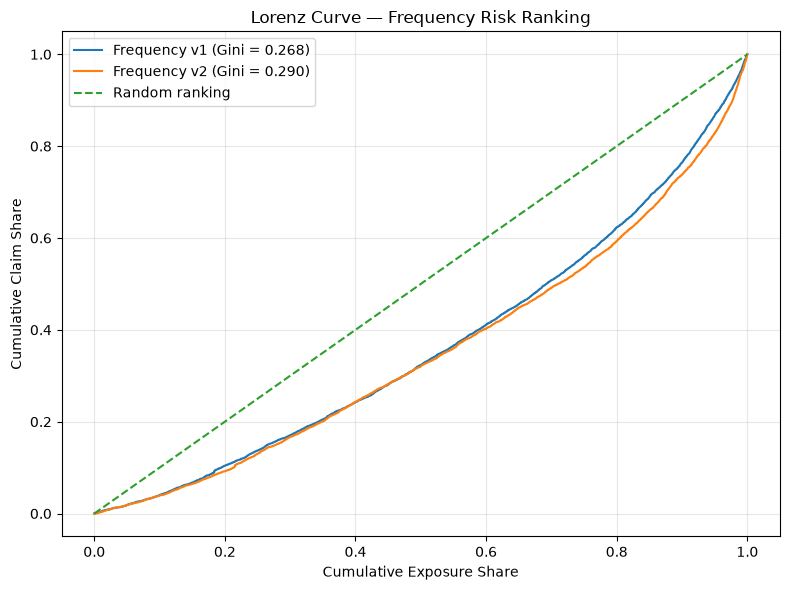

In [52]:
plt.figure(figsize=(8, 6))

plt.plot(
    frequency_v1_lorenz_x,
    frequency_v1_lorenz_y,
    label=f"Frequency v1 (Gini = {frequency_v1_gini:.3f})",
)

plt.plot(
    frequency_v2_lorenz_x,
    frequency_v2_lorenz_y,
    label=f"Frequency v2 (Gini = {frequency_v2_gini:.3f})",
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random ranking",
)

plt.xlabel("Cumulative Exposure Share")
plt.ylabel("Cumulative Claim Share")
plt.title("Lorenz Curve — Frequency Risk Ranking")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Ergebnis

Die Frequency-v2-Spezifikation verbessert neben der Poisson-Deviance auch
die Risikodifferenzierung.

Der Gini-Koeffizient steigt auf dem Holdout von **0,2683** bei Frequency v1
auf **0,2903** bei Frequency v2. Dies entspricht einer relativen Verbesserung
von rund **8,2 %**.

Frequency v2 trennt damit Policen mit niedrigem und hohem Schadenrisiko
besser und bestätigt die Verbesserung aus Cross-Validation und
Holdout-Deviance auch hinsichtlich des Risk Rankings.

In [54]:
FREQUENCY_V2_MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "frequency_poisson_quantile_spline_holdout_v2.joblib"
)

joblib.dump(
    final_frequency_v2_pipeline,
    FREQUENCY_V2_MODEL_PATH,
)

print("=== Frequency v2 Artifact ===")
print(f"Saved:  {FREQUENCY_V2_MODEL_PATH}")
print(f"Exists: {FREQUENCY_V2_MODEL_PATH.exists()}")

=== Frequency v2 Artifact ===
Saved:  c:\Users\Mesut\Desktop\kfz-insurance-risk-platform\models\frequency_poisson_quantile_spline_holdout_v2.joblib
Exists: True
